In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


iris = datasets.load_iris()
data = pd.DataFrame(data=iris.data, columns=iris.feature_names)
data["output"] = iris.target
data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),output
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [52]:
X = data[iris.feature_names]
Y = data["output"]

In [61]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=42)

In [54]:
model = RandomForestClassifier(n_estimators=100)
model.fit(X_train, Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [55]:
y_pred = model.predict(X_test)
accuracy_score(Y_test, y_pred)

0.3288590604026846

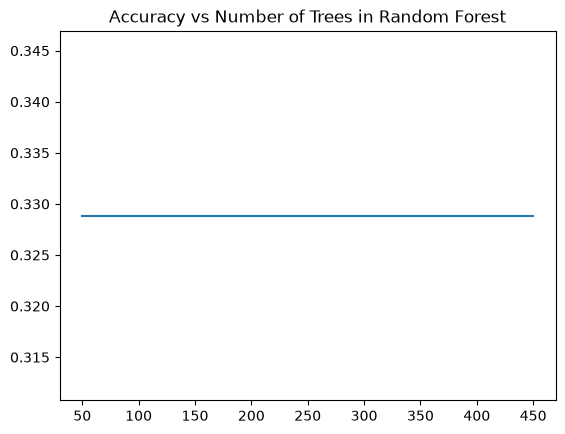

In [56]:
accuracy_list = []
for i in range(50, 500, 50):
    model = RandomForestClassifier(n_estimators=i)
    model.fit(X_train, Y_train)
    y_pred = model.predict(X_test)
    accuracy_list.append(accuracy_score(Y_test, y_pred))

plt.plot(range(50, 500, 50), accuracy_list)
plt.title("Accuracy vs Number of Trees in Random Forest")
plt.show()    


In [62]:
from sklearn.tree import export_graphviz
import pydot


tree = model.estimators_[10]
export_graphviz(tree, out_file='tree.dot', feature_names=iris.feature_names)


In [ ]:
# Graphviz's "dot" executable isn't on PATH, so pydot.write_png() fails.
# sklearn's plot_tree draws the same tree with matplotlib only - no external binary.
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    model.estimators_[10],
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title("A single tree from the Random Forest (estimator #10)")
plt.show()

## Which features does the forest actually use?

In [ ]:
importances = pd.Series(model.feature_importances_, index=iris.feature_names)
importances = importances.sort_values()

importances.plot(kind="barh")
plt.xlabel("Mean decrease in impurity")
plt.title("Feature importance")
plt.tight_layout()
plt.show()

importances.sort_values(ascending=False)

## Where does it get things wrong?

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

y_pred = model.predict(X_test)

cm = confusion_matrix(Y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()

print(classification_report(Y_test, y_pred, target_names=iris.target_names))

## Does a single tree do any worse?

A 30-row test set is tiny, so a single train/test split is noisy. Cross-validation gives a fairer comparison.

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

tree_scores = cross_val_score(DecisionTreeClassifier(random_state=42), X, Y, cv=5)
forest_scores = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), X, Y, cv=5)

print(f"Decision tree : {tree_scores.mean():.3f} +/- {tree_scores.std():.3f}")
print(f"Random forest : {forest_scores.mean():.3f} +/- {forest_scores.std():.3f}")